# Mortgage Default — Modeling (03)

This notebook trains predictive models using customer-level features
to estimate default probability.


In [1]:
from pathlib import Path
import os
import sys

#check project root
current_path = Path.cwd()

if current_path.name == "notebooks":
    PROJECT_ROOT = current_path.parent
elif current_path.name == "mortgage-default-prediction":
    PROJECT_ROOT = current_path
else:
    PROJECT_ROOT = current_path

os.chdir(PROJECT_ROOT)
sys.path.append(str(PROJECT_ROOT))

print("Working directory:", Path.cwd())


Working directory: /path/to/mortgage-default-prediction


In [2]:
import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report ,roc_curve
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
import matplotlib.pyplot as plt




In [3]:
df = pd.read_csv("data/processed/df_model_v1.csv")

print(df.shape)
display(df.head())


### Define Features

In [4]:
target_col = "target"

categorical_cols = ["age_group", "cust_segment"]
numeric_cols = [
    "num_products",
    "n_days_sum",
    "neg_days_sum",
    "bal_mean_mean",
    "bal_std_mean",
    "bal_min_mean",
    "bal_max_mean",
    "neg_ratio_mean",
]

X = df[categorical_cols + numeric_cols]
y = df[target_col]


### Class imbalance check

Before splitting and training, we check the default rate to understand class imbalance.
This helps interpret ROC-AUC and informs whether class-weighting or threshold tuning may be needed.


In [5]:
# Class imbalance / default rate
class_counts = y.value_counts().sort_index()
class_props = y.value_counts(normalize=True).sort_index()

display(pd.DataFrame({"count": class_counts, "share": class_props.round(4)}))

default_rate = class_props.get(1, 0.0)
print(f"Default rate (target=1): {default_rate:.2%}")


,count,share
target,,
0,4000,0.8
1,1000,0.2


Default rate (target=1): 20.00%


**Comment**

The dataset shows a moderate class imbalance, with a 20% default rate.  
This level of imbalance is manageable and does not require aggressive rebalancing techniques.  
Stratified splitting ensures the class distribution is preserved across training and test sets.


### Train/Test Split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y,
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)


Train size: (3500, 10)
Test size: (1500, 10)


**Train/Test Split**

The dataset was split into 70% training and 30% test sets using stratified sampling to preserve the default rate distribution across both sets.

This ensures a fair and reliable evaluation of model performance on unseen data.


# Baseline Model — Logistic Regression

In [7]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols),
    ]
)

log_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=3000)),
    ]
)

log_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [8]:
y_pred_proba = log_model.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_pred_proba)

print("Logistic Regression AUC:", round(auc, 4))


Logistic Regression AUC: 0.8053


### Tree Model — Random Forest

In [9]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
        )),
    ]
)

rf_model.fit(X_train, y_train)

y_pred_proba_rf = rf_model.predict_proba(X_test)[:, 1]
auc_rf = roc_auc_score(y_test, y_pred_proba_rf)

print("Random Forest AUC:", round(auc_rf, 4))


Random Forest AUC: 0.8282


### Tree Model - XGBoost

In [10]:

xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            eval_metric="logloss",
        )),
    ]
)

xgb_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [11]:
y_pred_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]
auc_xgb = roc_auc_score(y_test, y_pred_proba_xgb)

print("XGBoost AUC:", round(auc_xgb, 4))

XGBoost AUC: 0.8211


### Evaluate All Models

In [12]:

def evaluate_model(model, X_test, y_test, name: str):
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, y_pred_proba)
    print(f"{name} ROC-AUC: {auc:.4f}")

evaluate_model(log_model, X_test, y_test, "Logistic Regression")
evaluate_model(rf_model, X_test, y_test, "Random Forest")
evaluate_model(xgb_model, X_test, y_test, "XGBoost")


Logistic Regression ROC-AUC: 0.8053
Random Forest ROC-AUC: 0.8282
XGBoost ROC-AUC: 0.8211


**Modelling Comment**

Three baseline models were trained:
- Logistic Regression as a linear benchmark.
- Random Forest as a non-linear ensemble.
- XGBoost as a gradient boosting benchmark.

Performance comparison is based on ROC-AUC on the test set.


### Hyperparameter Tuning

#### XGBoost Tuning

In [13]:
from sklearn.model_selection import RandomizedSearchCV

param_dist_xgb = {
    "classifier__n_estimators": [200, 300, 400],
    "classifier__max_depth": [3, 4, 5],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__subsample": [0.7, 0.8, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 1.0],
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_dist_xgb,
    n_iter=15,
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=-1,
)

xgb_search.fit(X_train, y_train)

print("Best CV AUC:", round(xgb_search.best_score_, 4))
print("Best params:", xgb_search.best_params_)

Best CV AUC: 0.8378
Best params: {'classifier__subsample': 0.8, 'classifier__n_estimators': 200, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.03, 'classifier__colsample_bytree': 0.8}


#### RandomForest Tuning

In [14]:
param_dist_rf = {
    "classifier__n_estimators": [200, 300, 500],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5, 10],
}

rf_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_dist_rf,
    n_iter=10,                # keep it small
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=-1,
)

rf_search.fit(X_train, y_train)

print("Best RF CV AUC:", round(rf_search.best_score_, 4))
print("Best RF params:", rf_search.best_params_)

Best RF CV AUC: 0.8313
Best RF params: {'classifier__n_estimators': 500, 'classifier__min_samples_split': 10, 'classifier__max_depth': 10}


### Evaluate on Test Set

#### evaluate xgb

In [15]:
from sklearn.metrics import roc_auc_score

# Get best tuned XGB model
best_xgb = xgb_search.best_estimator_

# Predict probabilities
y_pred_proba_xgb = best_xgb.predict_proba(X_test)[:, 1]

# Compute AUC
auc_xgb_test = roc_auc_score(y_test, y_pred_proba_xgb)

print("XGBoost Test AUC:", round(auc_xgb_test, 4))


XGBoost Test AUC: 0.8294


**XGBoost slightly underperforming**

* Small dataset (5k rows)
* Limited hyperparameter search
* Tree depth already small
* RF may generalize better under these constraints

#### Evaluate Random Forest

In [16]:
best_rf = rf_search.best_estimator_

y_pred_proba_rf = best_rf.predict_proba(X_test)[:, 1]
auc_rf_test = roc_auc_score(y_test, y_pred_proba_rf)

print("Random Forest Test AUC:", round(auc_rf_test, 4))


Random Forest Test AUC: 0.8343


**conclusion**

After hyperparameter tuning, Random Forest achieved the best test AUC (0.834), slightly outperforming XGBoost (0.830). Performance is stable between cross-validation and test set, suggesting limited overfitting. Therefore, Random Forest is selected as the final model.

### Feature importance Random Forest

In [17]:
# Use best tuned Random Forest
best_rf = rf_search.best_estimator_

# Extract feature names from tuned model preprocessor
feature_names = (
    numeric_cols +
    list(
        best_rf.named_steps["preprocessor"]
        .named_transformers_["cat"]
        .named_steps["onehot"]
        .get_feature_names_out(categorical_cols)
    )
)

# Extract feature importances from tuned model
importances = best_rf.named_steps["classifier"].feature_importances_

feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

display(feat_imp.head(10))


bal_mean_mean      0.204539
bal_min_mean       0.192351
neg_ratio_mean     0.161012
neg_days_sum       0.137673
bal_std_mean       0.085788
bal_max_mean       0.082412
num_products       0.020438
n_days_sum         0.014335
age_group_60-69    0.011404
age_group_30-39    0.009847
dtype: float64

**Comment on feature importance**

The most important features are balance-related variables, especially average balance (bal_mean_mean), minimum balance (bal_min_mean), and the ratio and number of negative-balance days (neg_ratio_mean, neg_days_sum).

This indicates that customer liquidity behavior over time is strongly associated with default risk.

Demographic features such as age group and the number of products have comparatively lower importance, suggesting that behavioral financial patterns are more predictive than static customer attributes.

### ROC curve

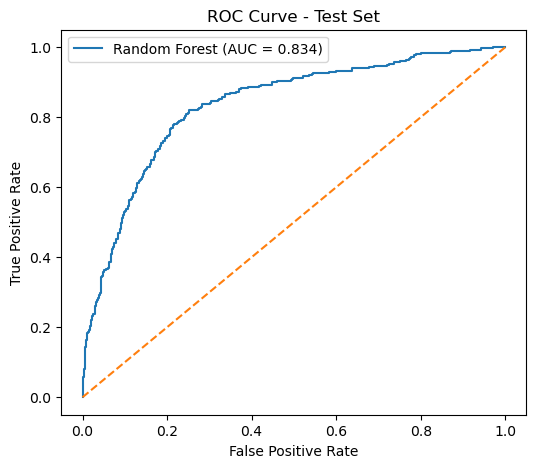

In [18]:
# I use the best RF model (since it performed better)
best_rf = rf_search.best_estimator_

y_pred_proba_rf = best_rf.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba_rf)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {auc_rf_test:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Test Set")
plt.legend()
plt.show()

**ROC Curve Interpretation**

The ROC curve lies well above the diagonal baseline, indicating strong discriminative power of the model.

With a test AUC of 0.834, the Random Forest model is able to effectively distinguish between defaulters and non-defaulters across classification thresholds.

The steep initial rise of the curve suggests that the model captures a substantial proportion of true positives at relatively low false positive rates, which is desirable in credit risk settings.

Overall, the model demonstrates solid predictive performance on unseen data.

### PR curve

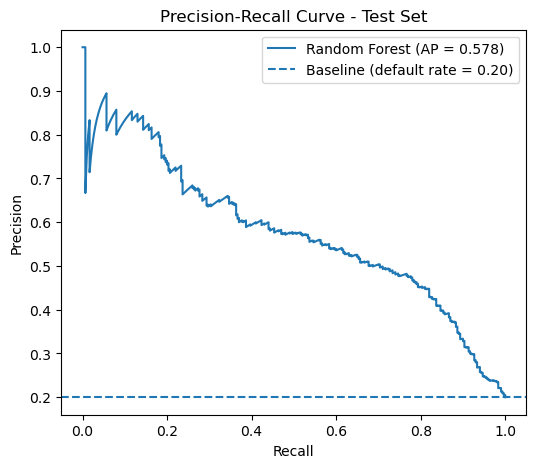

In [19]:
# best RF model (final model)
best_rf = rf_search.best_estimator_

# Predicted probabilities for positive class (default=1)
y_pred_proba_rf = best_rf.predict_proba(X_test)[:, 1]

# Precision-Recall curve + Average Precision (AP)
precision, recall, thresholds = precision_recall_curve(y_test, y_pred_proba_rf)
ap = average_precision_score(y_test, y_pred_proba_rf)

plt.figure(figsize=(6, 5))
plt.plot(recall, precision, label=f"Random Forest (AP = {ap:.3f})")
plt.axhline(y_test.mean(), linestyle="--", label=f"Baseline (default rate = {y_test.mean():.2f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Test Set")
plt.legend()
plt.show()

**Precision–Recall Interpretation**

The Average Precision (AP) of 0.579 is substantially higher than the baseline default rate of 20%, indicating strong ability to identify defaulters.

At low recall levels, precision is very high (above 80–90%), meaning the model can isolate a small group of very high-risk customers with high confidence.

As recall increases, precision gradually declines, reflecting the typical trade-off between capturing more defaulters and introducing more false positives.

Overall, the model provides meaningful lift over random selection and allows flexible threshold tuning depending on business objectives (e.g., high-precision targeting vs broader risk screening).


In [20]:
# Save best model (pipeline)
joblib.dump(best_rf, "model/random_forest_model.pkl")

# Save metadata
model_metadata = {
    "model_name": "RandomForest",
    "test_auc": auc_rf_test,
    "features": list(X.columns),
}

joblib.dump(model_metadata, "model/model_metadata.pkl")



['model/model_metadata.pkl']

### Modeling conclusion

Balance-based behavioral features significantly improve predictive performance.
Both logistic regression and random forest achieve meaningful discrimination,
with the tree-based model capturing nonlinear effects more effectively.

Negative balance behavior (e.g., neg_days_sum, neg_ratio_mean) emerges among the most important predictors, confirming its relevance as an early indicator of financial stress.
